# UAVDT (UAV-benchmark-M) – Keşifsel Veri Analizi (EDA)

Bu defterde UAVDT veri setinin tespit (DET) için kullanılan M kısmı incelenmektedir: dizi/kare/kutu sayıları, etiket durumu, sınıf dağılımı, görüntü özellikleri ve kutu boyutları.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

KOK = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(KOK))

from src.uavdt_okuma import uavdt_oku, bolum_haritasi, SINIF_ADLARI

UAVDT = KOK / "data" / "UAVDT"
GORUNTULER = UAVDT / "UAV-benchmark-M"
FIGURLER = KOK / "reports" / "figures"
FIGURLER.mkdir(parents=True, exist_ok=True)

print("Kök klasör:", KOK)

Kök klasör: c:\Users\betul\Documents\uyz_uav_object_detection


In [2]:
df = uavdt_oku(UAVDT)
print("Toplam kutu sayısı:", len(df))
df.head()


UAVDT: 100%|██████████| 50/50 [00:01<00:00, 29.38it/s]

Toplam kutu sayısı: 798795


,frame,target_id,x,y,w,h,out_of_view,occlusion,category,sinif,dizi,dosya,bolum
0,1,1,141,147,106,45,1,1,3,bus,M0101,img000001,train
1,2,1,138,147,106,45,1,1,3,bus,M0101,img000002,train
2,3,1,136,148,106,45,1,1,3,bus,M0101,img000003,train
3,4,1,134,148,106,45,1,1,3,bus,M0101,img000004,train
4,5,1,131,149,106,45,1,1,3,bus,M0101,img000005,train


In [3]:
harita = bolum_haritasi(UAVDT)

ozet = []
for bolum in ["train", "test"]:
    diziler = [dizi for dizi, b in harita.items() if b == bolum]

    kare_sayisi = 0
    seyrek_kare = 0
    for dizi in diziler:
        kareler = sorted((GORUNTULER / dizi).glob("*.jpg"))
        kare_sayisi += len(kareler)
        seyrek_kare += len(kareler[::10])

    d = df[df["bolum"] == bolum]
    etiketli = d[["dizi", "frame"]].drop_duplicates().shape[0]

    ozet.append({
        "bölüm": bolum,
        "dizi": len(diziler),
        "kare": kare_sayisi,
        "etiketli kare": etiketli,
        "etiketsiz kare": kare_sayisi - etiketli,
        "kutu": len(d),
        "10'da 1 örnekleme sonrası kare": seyrek_kare,
    })

ozet_df = pd.DataFrame(ozet)
ozet_df["kare başına kutu"] = (ozet_df["kutu"] / ozet_df["etiketli kare"]).round(1)
ozet_df

,bölüm,dizi,kare,etiketli kare,etiketsiz kare,kutu,10'da 1 örnekleme sonrası kare,kare başına kutu
0,train,30,24143,23829,314,422911,2426,17.7
1,test,20,16592,16580,12,375884,1667,22.7


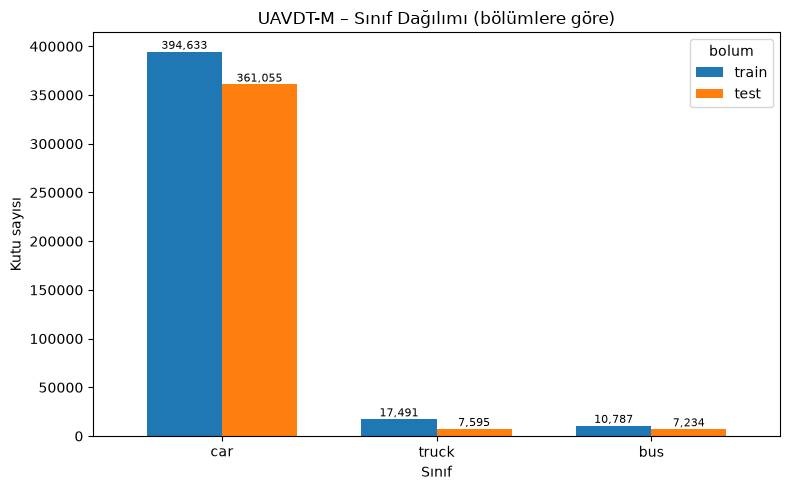

Bölüm içindeki yüzdeler:


bolum,train,test
sinif,,
car,93.3,96.1
truck,4.1,2.0
bus,2.6,1.9


In [4]:
dagilim = pd.crosstab(df["sinif"], df["bolum"])
dagilim = dagilim[["train", "test"]].loc[["car", "truck", "bus"]]

ax = dagilim.plot(kind="bar", figsize=(8, 5), width=0.7)
for kap in ax.containers:
    ax.bar_label(kap, fmt="{:,.0f}", fontsize=8)
ax.set_title("UAVDT-M – Sınıf Dağılımı (bölümlere göre)")
ax.set_xlabel("Sınıf")
ax.set_ylabel("Kutu sayısı")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(FIGURLER / "uavdt_sinif_dagilimi.png", dpi=150)
plt.show()

yuzde = (dagilim / dagilim.sum() * 100).round(1)
print("Bölüm içindeki yüzdeler:")
yuzde


In [5]:
from PIL import Image
from tqdm import tqdm

bilgiler = []
for dizi, bolum in tqdm(harita.items(), desc="Diziler"):
    kareler = sorted((GORUNTULER / dizi).glob("*.jpg"))[::10]
    for yol in kareler:
        with Image.open(yol) as img:
            bilgiler.append({
                "bolum": bolum,
                "dizi": dizi,
                "genislik": img.width,
                "yukseklik": img.height,
                "mod": img.mode,
            })

goruntu_df = pd.DataFrame(bilgiler)
print("İncelenen kare sayısı:", len(goruntu_df))
print()
print("Renk modu dağılımı:")
print(goruntu_df["mod"].value_counts())
print()
print("Görüntü boyutları (genişlik x yükseklik):")
goruntu_df.groupby(["genislik", "yukseklik"]).size().sort_values(ascending=False)

Diziler: 100%|██████████| 50/50 [00:20<00:00,  2.40it/s]

İncelenen kare sayısı: 4093

Renk modu dağılımı:
mod
RGB    4093
Name: count, dtype: int64

Görüntü boyutları (genişlik x yükseklik):


genislik  yukseklik
1024      540          3902
960       540           191
dtype: int64

Kutu boyut grupları (% olarak):


boyut,küçük (<32²),orta (32²–96²),büyük (>96²)
bolum,,,
train,50.2,48.4,1.4
test,74.9,23.0,2.1


Medyan kutu boyutu (√alan, piksel): 28.2


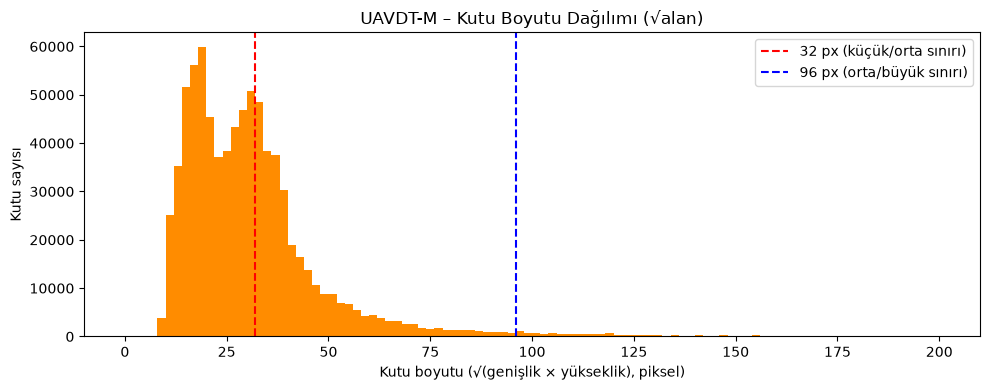

In [6]:
kutular = df.copy()
kutular["alan"] = kutular["w"] * kutular["h"]
kutular["boyut"] = pd.cut(
    kutular["alan"],
    bins=[0, 32**2, 96**2, float("inf")],
    labels=["küçük (<32²)", "orta (32²–96²)", "büyük (>96²)"],
    right=False,
)

boyut_oran = (pd.crosstab(kutular["bolum"], kutular["boyut"], normalize="index") * 100).round(1)
boyut_oran = boyut_oran.loc[["train", "test"]]
print("Kutu boyut grupları (% olarak):")
display(boyut_oran)

kutular["kenar"] = np.sqrt(kutular["alan"])
print("Medyan kutu boyutu (√alan, piksel):", round(kutular["kenar"].median(), 1))

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(kutular["kenar"], bins=100, range=(0, 200), color="darkorange")
ax.axvline(32, color="red", linestyle="--", label="32 px (küçük/orta sınırı)")
ax.axvline(96, color="blue", linestyle="--", label="96 px (orta/büyük sınırı)")
ax.set_title("UAVDT-M – Kutu Boyutu Dağılımı (√alan)")
ax.set_xlabel("Kutu boyutu (√(genişlik × yükseklik), piksel)")
ax.set_ylabel("Kutu sayısı")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURLER / "uavdt_kutu_boyutu.png", dpi=150)
plt.show()


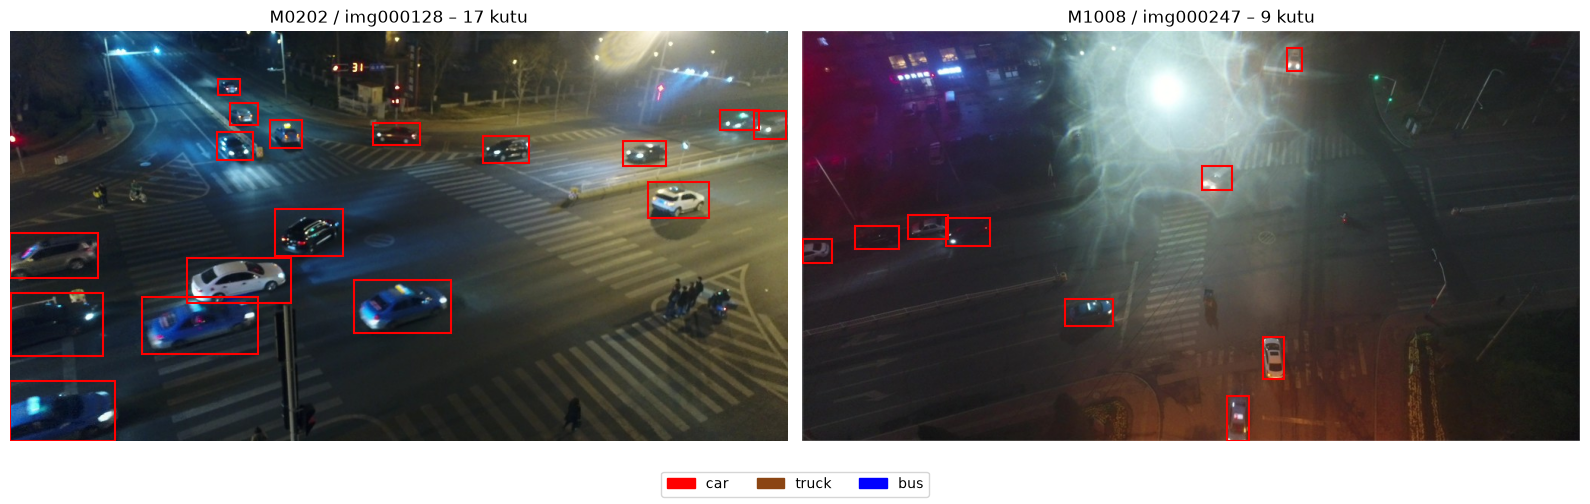

In [7]:
import matplotlib.patches as patches

renkler = {1: "red", 2: "saddlebrown", 3: "blue"}

rng = np.random.default_rng(42)
train_diziler = sorted(df.loc[df["bolum"] == "train", "dizi"].unique())
secilen_diziler = rng.choice(train_diziler, size=2, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, dizi in zip(axes, secilen_diziler):
    d = df[df["dizi"] == dizi]
    kare = rng.choice(d["frame"].unique())
    etiketler = d[d["frame"] == kare]

    img = Image.open(GORUNTULER / dizi / f"img{kare:06d}.jpg")
    ax.imshow(img)
    for _, k in etiketler.iterrows():
        ax.add_patch(patches.Rectangle((k["x"], k["y"]), k["w"], k["h"],
                                       fill=False, edgecolor=renkler[k["category"]], linewidth=1.5))
    ax.set_title(f"{dizi} / img{kare:06d} – {len(etiketler)} kutu")
    ax.axis("off")

lejant = [patches.Patch(color=renkler[c], label=SINIF_ADLARI[c]) for c in [1, 2, 3]]
fig.legend(handles=lejant, loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig(FIGURLER / "uavdt_ornek_etiketler.png", dpi=150)
plt.show()

In [8]:
print("=== readme.txt ===")
print((UAVDT / "M_attr" / "readme.txt").read_text(encoding="utf-8", errors="replace"))
print()
print("=== M0101_attr.txt ===")
print((UAVDT / "M_attr" / "train" / "M0101_attr.txt").read_text(encoding="utf-8", errors="replace"))

=== readme.txt ===
The format of the sequence-level attributes for each sequence is set as
daylight, night, fog; low-alt, medium-alt, high-alt; front-view, side-view,	bird-view; long-term.


=== M0101_attr.txt ===
1,0,0,0,1,0,1,1,0,0



In [9]:
OZELLIKLER = [
    "daylight", "night", "fog",
    "low-alt", "medium-alt", "high-alt",
    "front-view", "side-view", "bird-view",
    "long-term",
]

satirlar = []
for bolum in ["train", "test"]:
    for dosya in sorted((UAVDT / "M_attr" / bolum).glob("*_attr.txt")):
        degerler = [int(v) for v in dosya.read_text().strip().split(",")]
        kayit = {"dizi": dosya.name[:5], "bolum": bolum}
        kayit.update(dict(zip(OZELLIKLER, degerler)))
        satirlar.append(kayit)

attr = pd.DataFrame(satirlar)


def secili_ozellikler(satir, adlar):
    """Verilen gruptaki değeri 1 olan özelliklerin adlarını '+' ile birleştirir."""
    secili = [ad for ad in adlar if satir[ad] == 1]
    return "+".join(secili) if secili else "yok"


attr["kosul"] = attr.apply(lambda s: secili_ozellikler(s, ["daylight", "night", "fog"]), axis=1)
attr["yukseklik"] = attr.apply(lambda s: secili_ozellikler(s, ["low-alt", "medium-alt", "high-alt"]), axis=1)

print("Dizi sayıları – uçuş yüksekliği:")
display(pd.crosstab(attr["yukseklik"], attr["bolum"]))
print("Dizi sayıları – çekim koşulu:")
display(pd.crosstab(attr["kosul"], attr["bolum"]))

kutular_attr = kutular.merge(attr[["dizi", "yukseklik", "kosul"]], on="dizi")

print("Kutuların yüksekliğe göre dağılımı (bölüm içinde %):")
display((pd.crosstab(kutular_attr["yukseklik"], kutular_attr["bolum"], normalize="columns") * 100).round(1))
print("Yüksekliğe göre medyan kutu boyutu (√alan, piksel):")
display(kutular_attr.pivot_table(index="yukseklik", columns="bolum", values="kenar", aggfunc="median").round(1))

Dizi sayıları – uçuş yüksekliği:


bolum,test,train
yukseklik,,
high-alt,2,1
low-alt,8,10
medium-alt,10,19


Dizi sayıları – çekim koşulu:


bolum,test,train
kosul,,
daylight,12,17
fog,3,5
night,5,8


Kutuların yüksekliğe göre dağılımı (bölüm içinde %):


bolum,test,train
yukseklik,,
high-alt,27.8,1.1
low-alt,26.6,32.9
medium-alt,45.6,66.0


Yüksekliğe göre medyan kutu boyutu (√alan, piksel):


bolum,test,train
yukseklik,,
high-alt,18.7,17.3
low-alt,36.4,34.3
medium-alt,21.8,31.2


## Bulgular (UAVDT-M)

- **Veri sayısı:** 50 video dizisi (30 train, 20 test); toplam 40.735 kare (train 24.143, test 16.592). Kaynaklarda geçen "~80.000 kare" UAVDT'nin tamamı (M + S) içindir; tespit için kullanılan M kısmı 40.735 karedir.
- **Etiket durumu:** 326 kare etiketsiz (314 train, 12 test). Ayrı bir doğrulama (val) bölümü yok; train'den dizi bazında ayrılacak.
- **Kutu sayısı:** 798.795 (train 422.911, test 375.884); kare başına ortalama 17,7 (train) / 22,7 (test) kutu.
- **Sınıf dağılımı:** Yalnızca car, truck, bus. Car train'de %93,3, test'te %96,1; truck %4,1 / %2,0; bus %2,6 / %1,9. Aşırı dengesizlik → sınıf bazında AP raporlanmalı.
- **Ardışık kareler:** 30 fps video karelerinde aynı nesne kareler arasında yalnızca birkaç piksel kayıyor → eğitim kümesi 10 karede bir örneklenecek (24.143 → 2.426 kare); test kümesi literatürle karşılaştırma için tam bırakılacak.
- **Renk ve boyut:** Tüm kareler RGB. Boyutlar 1024×540 (%95) ve 960×540 (%5); VisDrone'a göre düşük ve sabit çözünürlük.
- **Kutu boyutu:** Küçük nesne (<32²) oranı train'de %50,2, test'te %74,9; medyan kutu boyutu 28,2 px.
- **Ölçek farkı ve uçuş yüksekliği:** Medyan kutu boyutu yükseklikle azalıyor (low ~35 px, medium ~22–31 px, high ~18 px). Test kutularının %27,8'i yüksek irtifa dizilerinden gelirken train'de bu oran %1,1 → eğitim ve test arasında ölçek açısından dağılım farkı var.
- **Çekim koşulları:** Gündüz/gece/sis dizileri iki bölümde benzer oranlarda (train 17/8/5, test 12/5/3).
- **Etiket kontrolü:** Örnek karelerde kutular araçlarla örtüşüyor; format (sol üst x, y, genişlik, yükseklik) doğru yorumlanıyor.